# Phase 3: Preprocess all satellite data

1. Apply the MODIS quality-control mask. 2. Remove invalid and poor-quality observations. 3. Apply product scale factors. 4. Convert temperature to Celsius. 5. Clip to the two city boundaries. 6. Reproject to a common coordinate system. 7. Resample compatible layers to a common grid. 8. Handle missing observations carefully. 9. Save processed images with consistent dates.

Landsat: ST_K = DN x 0.00341802 + 149, ST_C = ST_K - 273.15, SR = DN x 0.0000275 - 0.2, with the official QA_PIXEL flags.

**Output:** clean, aligned rasters for Mumbai and Navi Mumbai in `data/processed/`. Terminal equivalent: `.venv\Scripts\python.exe scripts\preprocess_data.py`.

**Reading the maps below:** all maps use UTM zone 43N coordinates in kilometres (x = easting, y = northing), so distances can be read off the axes directly: 10 units = 10 km. Cyan outline = Mumbai, green outline = Navi Mumbai. White = no valid value (outside both cities, cloud, or no data).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from urban_heat import config, logs, plotting as P, preprocessing as pp
from urban_heat.grid import load_grids

log = logs.setup('phase3_notebook')
config.ensure_dirs()
pp.run_all()          # skips anything already processed

grids = load_grids(config.DATA / 'grids.json')
g1, g30 = grids['modis_1km'], grids['landsat_30m']
geoms = pp.city_geoms()
ids1 = pp.read(pp.P_MASKS / 'city_id_1km.tif')['city_id']
CHARTS = config.OUTPUTS / 'charts'

2026-11-17 12:25:41 INFO    phase3_notebook: log file: outputs\logs\phase3_notebook_20261117_122541.log


2026-11-17 12:25:48 INFO    device: using CUDA - NVIDIA GeForce RTX 4060 Laptop GPU, 8.6 GB, 24 SMs, compute 8.9 (torch 2.13.0+cu126, CUDA 12.6)


2026-11-17 12:28:15 INFO    phase3: city cells: 1 km Mumbai 470, Navi Mumbai 103 | 30 m Mumbai 528030, Navi Mumbai 116669


2026-11-17 12:28:15 INFO    phase3: MODIS: 1150 composites, CPU (8 threads; the 1 km grid is too small to gain from the GPU)


2026-11-17 12:28:19 INFO    phase3: MODIS mumbai: mean valid fraction 0.74 over 1149 composites


2026-11-17 12:28:19 INFO    phase3: MODIS navi_mumbai: mean valid fraction 0.72 over 1149 composites


... (3 outputs left out)

2026-11-17 12:28:24 INFO    phase3: WorldCover: 2 maps at 30 m (mode of 3x3 10 m pixels, CPU)


2026-11-17 12:28:24 INFO    phase3: ERA5-Land: 10/15 native cells are land; 99 city cells take the nearest land cell


2026-11-17 12:28:25 INFO    phase3: ERA5-Land: 0 files written (K -> C for temperatures, CPU)


2026-11-17 12:28:25 INFO    phase3: Phase 3 finished in 163 s


## Figure 3.1: How much of each city has a valid MODIS temperature, per 8-day composite
**What it shows:** for each MODIS 8-day composite (x-axis, 2001-2025), the share of the city's 1 km cells that kept a valid land-surface temperature after the quality filter (y-axis: 0 = none, 1 = every cell). Dots are individual composites; the line is the 1-year rolling median.

**How to read it:** low values are cloud, mostly the June-September monsoon, when MODIS cannot see the ground. Nothing is gap-filled: these gaps stay as missing observations (step 8).

Mumbai: mean valid share 0.74; composites with no valid cell: 96 of 1149
Navi Mumbai: mean valid share 0.72; composites with no valid cell: 171 of 1149


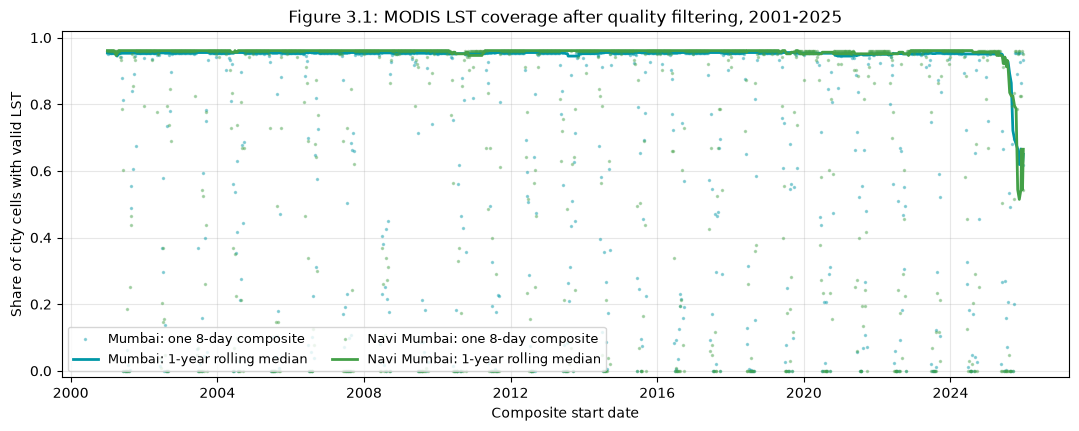

composites absent from the NASA archive: [datetime.date(2001, 6, 18)]


In [2]:
vf = pd.read_csv(config.PROCESSED / 'modis_valid_fraction.csv', parse_dates=['date'])
absent = sorted(vf.loc[vf.raw_file != 'present', 'date'].dt.date.unique())
present = vf[vf.raw_file == 'present']
fig, ax = plt.subplots(figsize=(13, 4.5))
for city, colour in [('mumbai', '#0097a7'), ('navi_mumbai', '#43a047')]:
    d = present[present.city == city].set_index('date').valid_fraction
    name = config.CITIES[city]
    ax.plot(d.index, d.values, '.', ms=3, alpha=0.35, color=colour, label=f'{name}: one 8-day composite')
    ax.plot(d.rolling(46, center=True, min_periods=10).median(), color=colour, lw=2, label=f'{name}: 1-year rolling median')
    print(f'{name}: mean valid share {d.mean():.2f}; composites with no valid cell: {(d == 0).sum()} of {len(d)}')
ax.set_ylim(-0.02, 1.02); ax.set_xlabel('Composite start date'); ax.set_ylabel('Share of city cells with valid LST')
ax.set_title('Figure 3.1: MODIS LST coverage after quality filtering, 2001-2025')
ax.legend(loc='lower left', ncol=2, fontsize=9); ax.grid(alpha=0.3)
P.save(fig, CHARTS / 'fig3_1_modis_valid_share_timeseries.png'); plt.show()
print('composites absent from the NASA archive:', absent)

## Figure 3.2: Average MODIS coverage by calendar month
**What it shows:** the same valid share as Figure 3.1, averaged over 2001-2025 for each month (bars), separately for each city. The number above each bar is that average.

**How to read it:** this shows which months the data can support. Dry months (roughly November-May) are well covered; monsoon months are sparse. This is why the plan uses March-May for seasonal comparison.

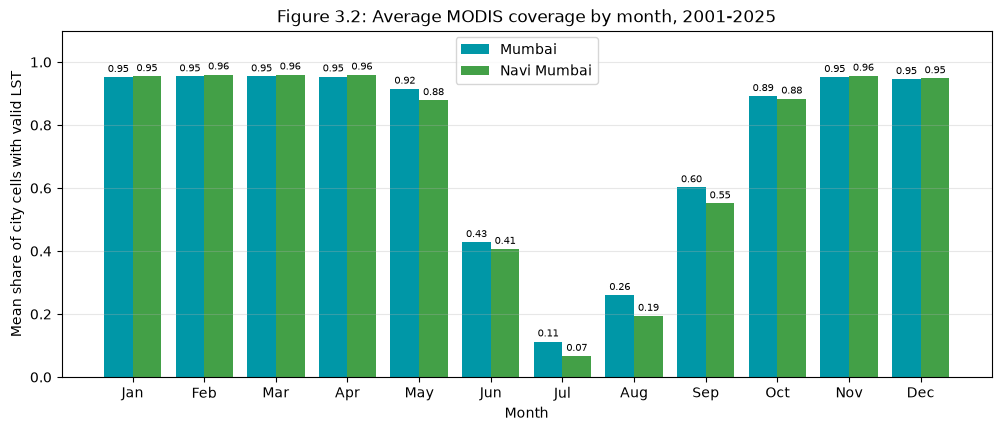

city   mumbai  navi_mumbai
month                     
1        0.95         0.95
2        0.95         0.96
3        0.95         0.96
4        0.95         0.96
5        0.92         0.88
6        0.43         0.41
7        0.11         0.07
8        0.26         0.19
9        0.60         0.55
10       0.89         0.88
11       0.95         0.96
12       0.95         0.95


In [3]:
monthly = present.assign(month=present.date.dt.month).pivot_table(index='month', columns='city', values='valid_fraction')
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(1, 13); w = 0.4
for off, (city, colour) in zip((-w / 2, w / 2), [('mumbai', '#0097a7'), ('navi_mumbai', '#43a047')]):
    bars = ax.bar(x + off, monthly[city], width=w, color=colour, label=config.CITIES[city])
    ax.bar_label(bars, fmt='%.2f', fontsize=7, padding=2)
ax.set_xticks(x, ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_ylim(0, 1.1); ax.set_xlabel('Month'); ax.set_ylabel('Mean share of city cells with valid LST')
ax.set_title('Figure 3.2: Average MODIS coverage by month, 2001-2025'); ax.legend(); ax.grid(axis='y', alpha=0.3)
P.save(fig, CHARTS / 'fig3_2_modis_valid_share_by_month.png'); plt.show()
print(monthly.round(2))

## Figure 3.3: Processed MODIS daytime land-surface temperature (one composite)
**What it shows:** MOD11A2 daytime LST in degrees Celsius for the 8-day composite starting 2024-04-06, after the quality filter, scaling (DN x 0.02 - 273.15) and clipping to the cities. Each square is one 1 km cell.

**How to read it:** brighter = hotter surface. This is the temperature of the ground and roofs at about 10:30 local time, not air temperature.

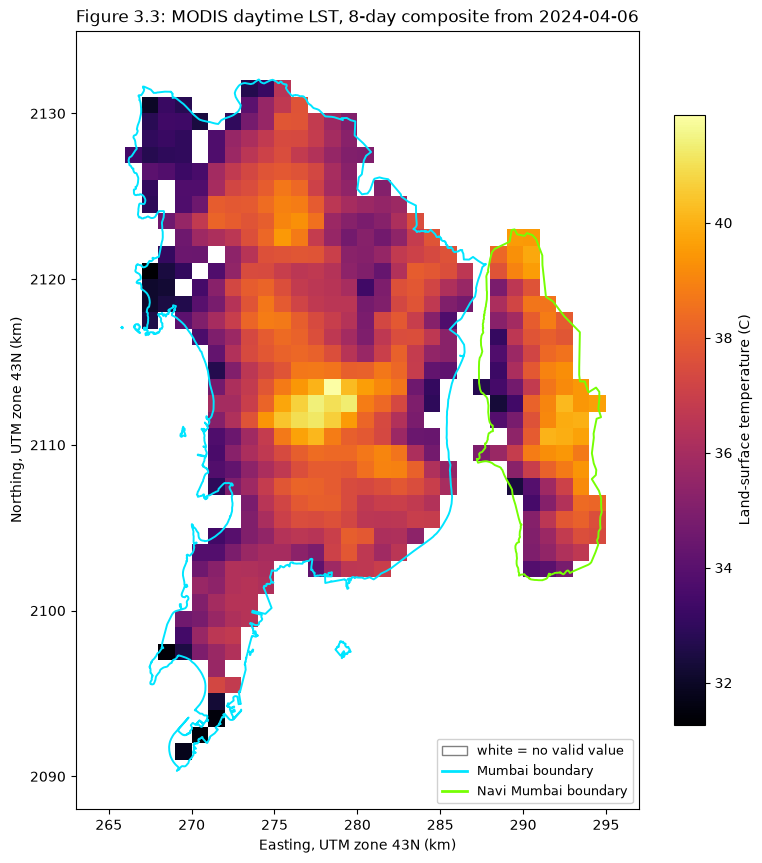

Mumbai: 449 of 470 cells valid; LST min 31.3 C, median 36.5 C, max 41.9 C
Navi Mumbai: 99 of 103 cells valid; LST min 32.3 C, median 37.7 C, max 40.2 C


In [4]:
lst = pp.read(pp.P_MODIS / 'MOD11A2_LST_C_20240406.tif')['lst_celsius']
fig, ax = P.raster_map(lst, g1, geoms, title='Figure 3.3: MODIS daytime LST, 8-day composite from 2024-04-06',
                       cbar_label='Land-surface temperature (C)')
P.save(fig, CHARTS / 'fig3_3_modis_lst_20240406.png'); plt.show()
for k, i in pp.CITY_IDS.items():
    v = lst[ids1 == i]; ok = np.isfinite(v)
    print(f'{config.CITIES[k]}: {ok.sum()} of {len(v)} cells valid; LST min {np.nanmin(v):.1f} C, '
          f'median {np.nanmedian(v):.1f} C, max {np.nanmax(v):.1f} C')

## Figure 3.4a: How much of the cities each Landsat scene covers
**What it shows:** each marker is one Landsat 8/9 scene (March-May of a selected year). y = share of the cities' 30 m pixels that lie inside the scene's footprint.

**How to read it:** Landsat images the area from two neighbouring orbit tracks. Scenes near 1 cover both cities completely. The many scenes at about 0.07 or 0 belong to a neighbouring track that only touches a corner of the area: this is footprint, not cloud.

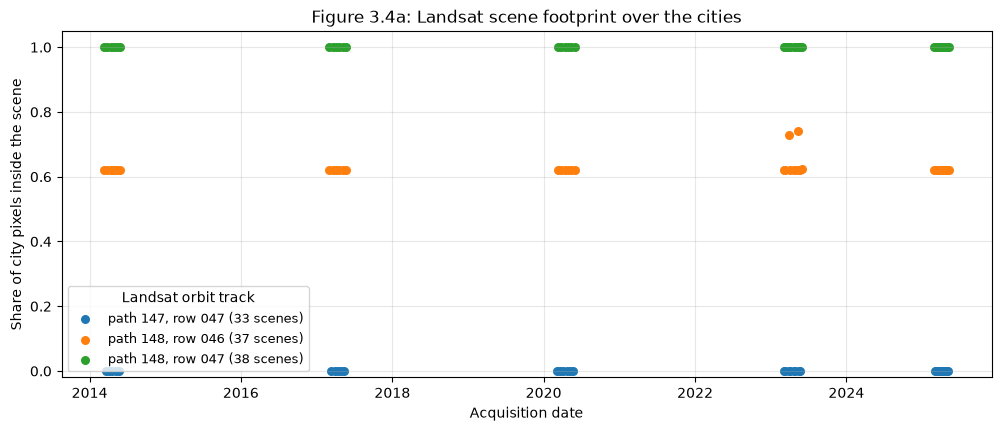

                   scenes  mean_coverage
track                                   
path 147, row 047      33          0.000
path 148, row 046      37          0.626
path 148, row 047      38          1.000


In [5]:
ls = pd.read_csv(config.PROCESSED / 'landsat_clear_fraction.csv', dtype={'date': str})
ls['when'] = pd.to_datetime(ls.date, format='%Y%m%d')
ls['sensor'] = ls.scene.str[:4].map({'LC08': 'Landsat 8', 'LC09': 'Landsat 9'})
ls['track'] = 'path ' + ls.scene.str[5:8] + ', row ' + ls.scene.str[8:11]
fig, ax = plt.subplots(figsize=(12, 4.5))
for track, d in ls.groupby('track'):
    ax.scatter(d.when, d.coverage_of_cities, s=30, label=f'{track} ({len(d)} scenes)')
ax.set_ylim(-0.02, 1.05); ax.set_xlabel('Acquisition date'); ax.set_ylabel('Share of city pixels inside the scene')
ax.set_title('Figure 3.4a: Landsat scene footprint over the cities'); ax.legend(title='Landsat orbit track', fontsize=9); ax.grid(alpha=0.3)
P.save(fig, CHARTS / 'fig3_4a_landsat_coverage.png'); plt.show()
print(ls.groupby('track').coverage_of_cities.agg(scenes='count', mean_coverage='mean').round(3))

## Figure 3.4b: How cloud-free the covered part is
**What it shows:** for scenes covering at least half of the cities (Figure 3.4a), the share of the covered pixels that remain after removing fill, cloud, dilated cloud, cirrus and cloud shadow with QA_PIXEL. Circles are Landsat 8, squares Landsat 9.

**How to read it:** 1 = completely clear; lower values mean cloud or haze removed part of the image. These clear scenes are the ones used for the detailed maps in Phase 5.

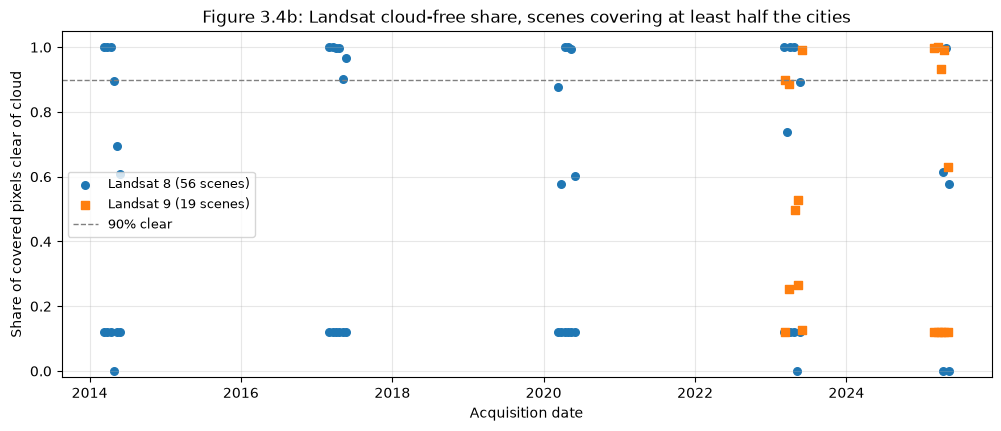

      scenes  median_clear  scenes_90pct_clear
date                                          
2014      12          0.36                   3
2017      12          0.51                   6
2020      12          0.35                   3
2023      19          0.50                   5
2025      20          0.35                   7


In [6]:
full = ls[ls.coverage_of_cities >= 0.5]
fig, ax = plt.subplots(figsize=(12, 4.5))
for sensor, marker in [('Landsat 8', 'o'), ('Landsat 9', 's')]:
    d = full[full.sensor == sensor]
    ax.scatter(d.when, d.clear_share_of_covered, marker=marker, s=30, label=f'{sensor} ({len(d)} scenes)')
ax.axhline(0.9, color='grey', ls='--', lw=1, label='90% clear')
ax.set_ylim(-0.02, 1.05); ax.set_xlabel('Acquisition date'); ax.set_ylabel('Share of covered pixels clear of cloud')
ax.set_title('Figure 3.4b: Landsat cloud-free share, scenes covering at least half the cities'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
P.save(fig, CHARTS / 'fig3_4b_landsat_clear_share.png'); plt.show()
print(full.groupby(full.date.str[:4]).agg(scenes=('scene', 'count'), median_clear=('clear_share_of_covered', 'median'),
                                          scenes_90pct_clear=('clear_share_of_covered', lambda v: int((v >= 0.9).sum()))).round(2))

## Figure 3.5: Processed Landsat surface temperature (clearest scene)
**What it shows:** Landsat surface temperature in degrees Celsius at 30 m for the clearest scene, after QA_PIXEL masking and scaling (DN x 0.00341802 + 149 - 273.15).

**How to read it:** the same quantity as Figure 3.3 at much finer detail. The thermal sensor measures at 100 m; the 30 m grid is delivered resampling, not extra thermal detail. Individual neighbourhoods, parks and water bodies are visible.

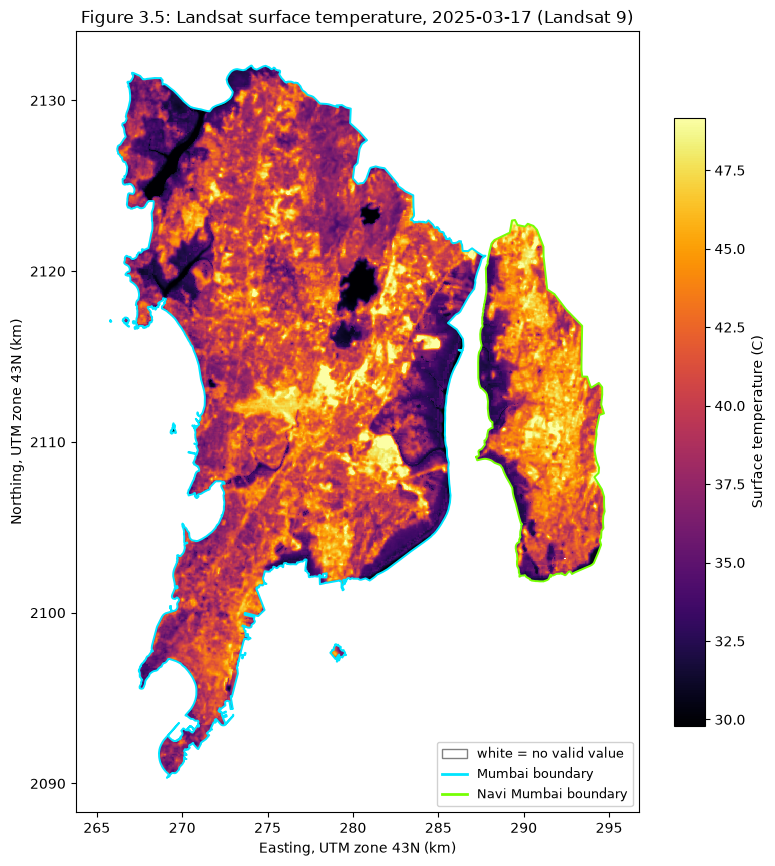

scene LC09_148047_20250317: 100% of city pixels clear; colour scale 29.8-49.2 C (1st-99th percentile); median 40.1 C


In [7]:
best = ls.sort_values('clear_fraction_in_cities').iloc[-1]      # most of both cities visible
st = pp.read(pp.landsat_out(best.scene))['st_celsius']
lo, hi = np.nanpercentile(st, [1, 99])
fig, ax = P.raster_map(st, g30, geoms, vmin=lo, vmax=hi, cbar_label='Surface temperature (C)',
                       title=f"Figure 3.5: Landsat surface temperature, {best.when:%Y-%m-%d} ({best.sensor})")
P.save(fig, CHARTS / 'fig3_5_landsat_st_clearest_scene.png'); plt.show()
print(f'scene {best.scene}: {100 * best.clear_fraction_in_cities:.0f}% of city pixels clear; '
      f'colour scale {lo:.1f}-{hi:.1f} C (1st-99th percentile); median {np.nanmedian(st):.1f} C')

## Figure 3.6: Land cover (ESA WorldCover 2021, resampled to 30 m)
**What it shows:** the WorldCover class of each 30 m cell inside the cities (the most common of its nine 10 m pixels). The legend gives each class's share of the combined city area.

**How to read it:** red is built-up, greens are vegetation and mangroves, blue is water. Comparing this with Figures 3.3 and 3.5 shows where heat and built-up land coincide.

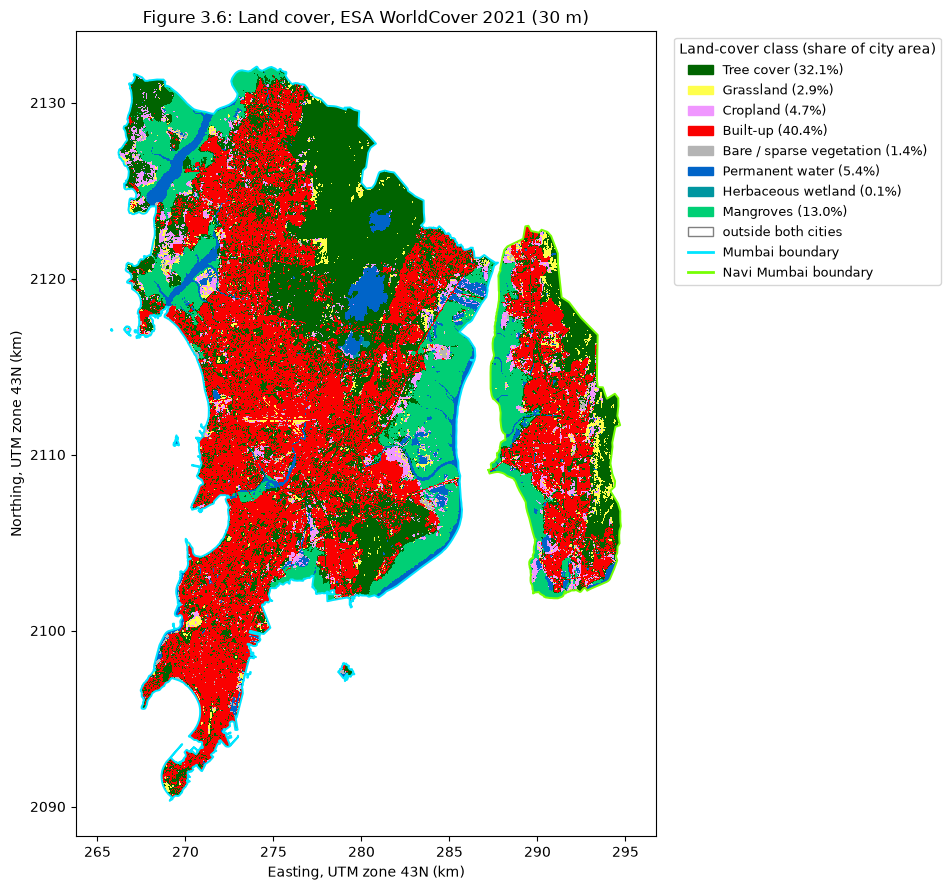

Mumbai {'Tree cover': '33.2%', 'Grassland': '2.4%', 'Cropland': '4.1%', 'Built-up': '40.6%', 'Bare / sparse vegetation': '1.5%', 'Permanent water': '5.9%', 'Herbaceous wetland': '0.1%', 'Mangroves': '12.3%'}
Navi Mumbai {'Tree cover': '27.2%', 'Grassland': '5.5%', 'Cropland': '7.6%', 'Built-up': '39.3%', 'Bare / sparse vegetation': '0.9%', 'Permanent water': '3.1%', 'Herbaceous wetland': '0.0%', 'Mangroves': '16.3%'}


In [8]:
wc = pp.read(pp.P_WORLDCOVER / 'worldcover_2021_30m.tif')['landcover']
fig, ax = P.worldcover_map(wc, g30, geoms, title='Figure 3.6: Land cover, ESA WorldCover 2021 (30 m)')
P.save(fig, CHARTS / 'fig3_6_worldcover_2021.png'); plt.show()
ids30 = pp.read(pp.P_MASKS / 'city_id_30m.tif')['city_id']
for k, i in pp.CITY_IDS.items():
    v = wc[ids30 == i]
    top = {P.WORLDCOVER_CLASSES[c][0]: f'{100 * (v == c).mean():.1f}%' for c in P.WORLDCOVER_CLASSES if (v == c).any()}
    print(config.CITIES[k], top)

## Figure 3.7: ERA5-Land 2 m air temperature on the 1 km grid
**What it shows:** ERA5-Land daily mean 2 m air temperature (degrees C) on 2024-04-06, copied onto the 1 km grid. Each block of identical colour is one ERA5-Land cell of about 9 km: the values are not interpolated, so no false fine-scale detail is created.

**How to read it:** this is regional weather, not neighbourhood temperature. Dotted cells sit under an ERA5-Land sea cell (ERA5-Land has no data over water), so they use the nearest land cell instead.

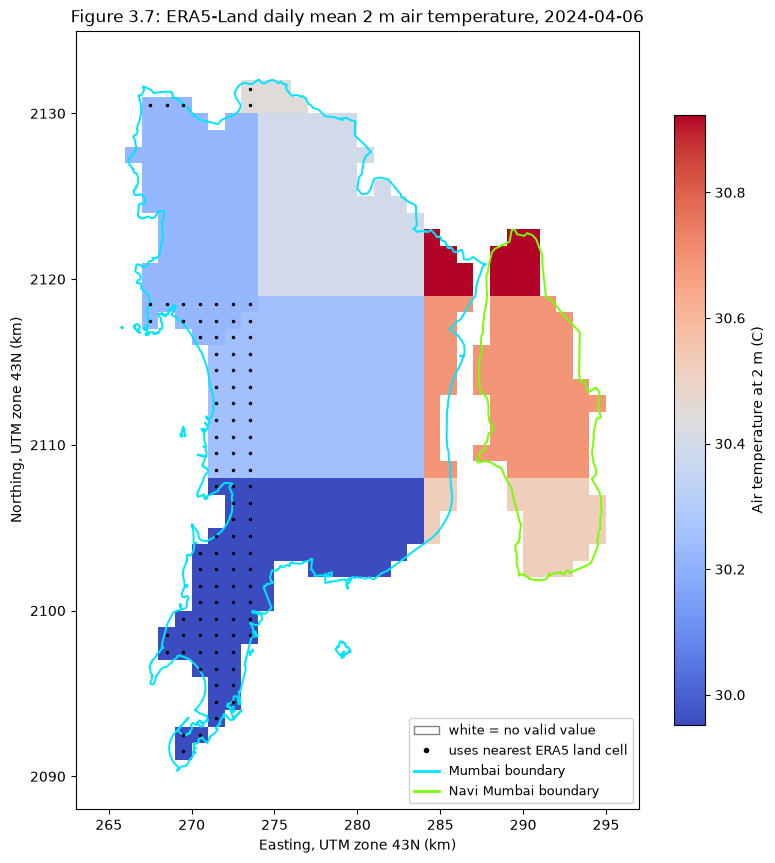

distinct ERA5 values over the cities: 8; range 30.0-30.9 C; city cells using nearest land cell: 99


In [9]:
from matplotlib.lines import Line2D
t2m = pp.read(pp.P_ERA5 / 'era5_temperature_2m_2024.tif')['20240406']
sub = pp.read(pp.P_MASKS / 'era5_nearest_land_substituted_1km.tif')['substituted'].astype(bool)
dot = Line2D([], [], marker='.', ls='', color='black', label='uses nearest ERA5 land cell')
fig, ax = P.raster_map(t2m, g1, geoms, cmap='coolwarm', cbar_label='Air temperature at 2 m (C)',
                       title='Figure 3.7: ERA5-Land daily mean 2 m air temperature, 2024-04-06',
                       extra_handles=[dot])
rows, cols = np.nonzero(sub)
x0, _, _, y1 = g1.bounds
ax.plot((x0 + (cols + 0.5) * g1.res) / 1000, (y1 - (rows + 0.5) * g1.res) / 1000, '.', color='black', ms=3)
P.save(fig, CHARTS / 'fig3_7_era5_t2m_20240406.png'); plt.show()
print(f'distinct ERA5 values over the cities: {np.unique(t2m[np.isfinite(t2m)].round(2)).size}; '
      f'range {np.nanmin(t2m):.1f}-{np.nanmax(t2m):.1f} C; city cells using nearest land cell: {sub.sum()}')